# Food-11 classification with DaViT Tiny

Train and evaluate a DaViT Tiny model on Food-11, then compare predictions with horizontal-flip test-time augmentation. Place the dataset under `food11/train` and `food11/test`; install PyTorch, torchvision, timm, TensorBoard, Pillow, NumPy, Matplotlib, seaborn, scikit-learn, and tqdm. Model weights download on the first run.

The saved outputs are from an earlier run and predate the corrected image filtering and validation transforms. Training can take more than an hour. The test set was used in several model comparisons, so its scores are exploratory.

**Data:** [Food image collection with 11 classes](https://github.com/InsiyaFakhruddin/Food_Classifier/tree/main/food11). Its 11,000 images match the local files used in this lesson. Place the `train/` and `test/` folders under `food11/`.

In [2]:
from PIL import Image

def valid_image(path):
    """Keep readable images of at least 50×50 pixels without modifying files."""
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            image.load()
            return min(image.size) >= 50
    except (OSError, ValueError):
        return False

from torchvision.models import ConvNeXt_Tiny_Weights, convnext_tiny
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, WeightedRandomSampler
from torchvision import datasets, transforms, models
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from torch.utils.data import Subset
from collections import Counter

data_dir = "food11"
train_dir = os.path.join(data_dir, "train")
test_dir = os.path.join(data_dir, "test")

batch_size = 32
num_epochs = 50
learning_rate_classifier = 1e-3
learning_rate_features = 1e-5

patience = 7  # Больше терпения при fine-tuning
best_acc = -float("inf")
patience_counter = 0

torch.manual_seed(42)
device = ("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_train_augmented = datasets.ImageFolder(train_dir, transform=train_transform, is_valid_file=valid_image)
full_train_clean = datasets.ImageFolder(train_dir, transform=val_test_transform, is_valid_file=valid_image)
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transform, is_valid_file=valid_image)
if full_train_augmented.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test folders must contain the same classes.")

# Split на train/val (80/20)
train_size = int(0.8 * len(full_train_augmented))
val_size = len(full_train_augmented) - train_size

indices = list(range(len(full_train_augmented)))
np.random.seed(42)
np.random.shuffle(indices)
train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(full_train_augmented, train_indices)
val_dataset = Subset(full_train_clean, val_indices)

num_classes = len(full_train_augmented.classes)
class_names = full_train_augmented.classes
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Классы ({num_classes}): {class_names}")

train_labels = [label for _, label in train_dataset]
class_counts = Counter(train_labels)
print("Распределение классов в train:", class_counts)

# Вычисляем веса для каждого класса
class_weights = [len(train_labels) / (num_classes * class_counts[i]) for i in range(num_classes)]
sample_weights = [class_weights[label] for label in train_labels]

# WeightedRandomSampler
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=sampler, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

model = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1)

in_features = model.classifier[-1].in_features
model.classifier[-1] = nn.Linear(in_features, num_classes)

for name, param in model.named_parameters():
    if "stages.2" in name or "stages.3" in name or "classifier" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

model = model.to(device)

print("Обучаемые параметры (ConvNeXt V2):")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"  [Train] {name}")

optimizer = optim.AdamW([  # AdamW — лучше для V2
    {'params': [p for n, p in model.named_parameters() if "stages.2" in n or "stages.3" in n], 'lr': 3e-6},
    {'params': model.classifier.parameters(), 'lr': 3e-4}
], weight_decay=1e-4)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1, weight=torch.tensor(class_weights).to(device))
scheduler = optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=15, T_mult=2)

writer = SummaryWriter(log_dir="runs/food11_ConvNeXt_V2")

def plot_confusion_matrix(cm, class_names, epoch):
    fig, ax = plt.subplots(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix - Epoch {epoch+1}')
    return fig

def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * np.mean(np.array(all_preds) == np.array(all_labels))
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    cm = confusion_matrix(all_labels, all_preds)

    return avg_loss, accuracy, precision, recall, f1, all_preds, all_labels, cm

start_time = time.time()
print("\nОбучение (fine-tuning + label smoothing + weighted sampling)")

for epoch in range(num_epochs):
    epoch_start = time.time()
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]", leave=False, ncols=100)

    for images, labels in train_pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_loss += loss.item()
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

        train_pbar.set_postfix({'loss': f'{loss.item():.3f}'})

    avg_train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total

    # Валидация
    val_loss, val_acc, val_prec, val_rec, val_f1, val_preds, val_labels, val_cm = evaluate_model(model, val_loader, criterion, device)

    # Логи
    writer.add_scalar("Loss/Train", avg_train_loss, epoch)
    writer.add_scalar("Loss/Validation", val_loss, epoch)
    writer.add_scalar("Accuracy/Train", train_acc, epoch)
    writer.add_scalar("Accuracy/Validation", val_acc, epoch)
    writer.add_scalar("Precision/Validation", val_prec, epoch)
    writer.add_scalar("Recall/Validation", val_rec, epoch)
    writer.add_scalar("F1/Validation", val_f1, epoch)
    writer.add_scalar("Learning_Rate_Classifier", optimizer.param_groups[1]['lr'], epoch)
    writer.add_scalar("Learning_Rate_Features", optimizer.param_groups[0]['lr'], epoch)

    if (epoch + 1) % 5 == 0:
        cm_fig = plot_confusion_matrix(val_cm, class_names, epoch)
        writer.add_figure("Confusion_Matrix/Validation", cm_fig, epoch)
        plt.close(cm_fig)

    scheduler.step(val_acc)

    epoch_time = time.time() - epoch_start
    elapsed = time.time() - start_time
    est_remaining = (elapsed / (epoch + 1)) * (num_epochs - (epoch + 1))

    print(f"Epoch {epoch+1:02d}/{num_epochs} | "
          f"Train: L={avg_train_loss:.3f} A={train_acc:.1f}% | "
          f"Val: L={val_loss:.3f} A={val_acc:.1f}% | "
          f"LR_c={optimizer.param_groups[1]['lr']:.2e} LR_f={optimizer.param_groups[0]['lr']:.2e} | "
          f"Time: {epoch_time:.0f}s | ETA: {est_remaining/60:.1f}min")

    # Early stopping
    if val_acc > best_acc:
        best_acc = val_acc
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_acc': best_acc,
            'class_names': class_names
        }, "ConvNeXt_V2_food11.pth")
        print(f"Лучшая модель сохранена! Val Acc: {best_acc:.2f}%")
    else:
        patience_counter += 1
        print(f"Нет улучшения {patience_counter}/{patience} эпох")
        if patience_counter >= patience:
            print(f"\nОстановка на эпохе {epoch+1}")
            print(f"Лучший результат: {best_acc:.2f}%")
            break


print("Финальная оценка на Test Set...")
checkpoint = torch.load("ConvNeXt_V2_food11.pth", map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])

test_loss, test_acc, test_prec, test_rec, test_f1, test_preds, test_labels, test_cm = evaluate_model(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.3f} | Accuracy: {test_acc:.2f}% | Precision: {test_prec:.3f} | Recall: {test_rec:.3f} | F1: {test_f1:.3f}")

# Сохраняем матрицу
cm_fig = plot_confusion_matrix(test_cm, class_names, -1)
cm_fig.savefig("confusion_matrix_ConvNeXt_V2.png")
plt.close(cm_fig)
print("Confusion matrix сохранена: confusion_matrix_ConvNeXt_V2.png")

total_time = time.time() - start_time
print(f"Общее время: {total_time/60:.1f} минут")
print(f"Лучшая Val Accuracy: {best_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Модель сохранена: ConvNeXt_V2_food11.pth")

writer.close()

Устройство: mps
Train: 7920 | Val: 1980 | Test: 1100
Классы (11): ['apple_pie', 'cheesecake', 'chicken_curry', 'french_fries', 'fried_rice', 'hamburger', 'hot_dog', 'ice_cream', 'omelette', 'pizza', 'sushi']
Распределение классов в train: Counter({2: 735, 6: 729, 5: 728, 0: 727, 10: 721, 9: 720, 4: 717, 8: 716, 1: 712, 7: 708, 3: 707})
Обучаемые параметры (ConvNeXt V2):
  [Train] classifier.0.weight
  [Train] classifier.0.bias
  [Train] classifier.2.weight
  [Train] classifier.2.bias

Обучение (fine-tuning + label smoothing + weighted sampling)


Epoch 01/50 | Train: L=1.479 A=67.9% | Val: L=0.992 A=83.4% | LR_c=8.59e-05 LR_f=8.59e-07 | Time: 227s | ETA: 185.3min
Лучшая модель сохранена! Val Acc: 83.43%


Epoch 02/50 | Train: L=1.096 A=79.1% | Val: L=0.958 A=84.1% | LR_c=8.13e-05 LR_f=8.13e-07 | Time: 235s | ETA: 184.8min
Лучшая модель сохранена! Val Acc: 84.09%


Epoch 03/50 | Train: L=1.040 A=81.3% | Val: L=0.933 A=85.2% | LR_c=7.40e-05 LR_f=7.40e-07 | Time: 237s | ETA: 182.7min
Лучшая модель сохранена! Val Acc: 85.15%


Epoch 04/50 | Train: L=1.026 A=81.2% | Val: L=0.917 A=85.6% | LR_c=7.09e-05 LR_f=7.09e-07 | Time: 242s | ETA: 180.5min
Лучшая модель сохранена! Val Acc: 85.61%


Epoch 05/50 | Train: L=1.020 A=81.4% | Val: L=0.910 A=85.8% | LR_c=6.99e-05 LR_f=6.99e-07 | Time: 258s | ETA: 180.0min
Лучшая модель сохранена! Val Acc: 85.76%


... (30 outputs left out)

Epoch 36/50 | Train: L=0.896 A=86.8% | Val: L=0.838 A=88.2% | LR_c=5.42e-05 LR_f=5.42e-07 | Time: 241s | ETA: 56.7min
Нет улучшения 4/7 эпох


Epoch 37/50 | Train: L=0.893 A=86.8% | Val: L=0.839 A=88.4% | LR_c=5.33e-05 LR_f=5.33e-07 | Time: 241s | ETA: 52.6min
Нет улучшения 5/7 эпох


Epoch 38/50 | Train: L=0.895 A=86.9% | Val: L=0.838 A=88.2% | LR_c=5.45e-05 LR_f=5.45e-07 | Time: 240s | ETA: 48.5min
Нет улучшения 6/7 эпох


Epoch 39/50 | Train: L=0.892 A=86.6% | Val: L=0.836 A=88.3% | LR_c=5.39e-05 LR_f=5.39e-07 | Time: 242s | ETA: 44.5min
Нет улучшения 7/7 эпох

Остановка на эпохе 39
Лучший результат: 88.38%
Финальная оценка на Test Set...
Test Loss: 0.849 | Accuracy: 88.55% | Precision: 0.890 | Recall: 0.885 | F1: 0.887
Confusion matrix сохранена: confusion_matrix_ConvNeXt_V2.png
Общее время: 158.1 минут
Лучшая Val Accuracy: 88.38%
Test Accuracy: 88.55%
Модель сохранена: ConvNeXt_V2_food11.pth


In [8]:
def tta_predict(model, loader, device):
    """Average predictions for the original image and its horizontal flip."""
    model.eval()
    predictions = []
    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            scores = torch.softmax(model(images), dim=1)
            scores += torch.softmax(model(torch.flip(images, dims=[-1])), dim=1)
            predictions.extend(scores.argmax(dim=1).cpu().tolist())
    return predictions

In [6]:
from torchvision.models import ConvNeXt_Tiny_Weights, convnext_tiny
import os
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split, WeightedRandomSampler
from torchvision import datasets, transforms, models
from torch.utils.tensorboard import SummaryWriter
from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
from torch.utils.data import Subset
from collections import Counter
import timm
import types

data_dir = "food11"
train_dir = os.path.join(data_dir, "train")
test_dir = os.path.join(data_dir, "test")

batch_size = 32
num_epochs = 50  # Увеличили — будем дообучать глубже
learning_rate_classifier = 1e-3
learning_rate_features = 1e-5  # Меньше для размороженных слоёв

patience = 7  # Больше терпения при fine-tuning
best_acc = -float("inf")
patience_counter = 0

# torch.manual_seed(42)
device = ("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

full_train_augmented = datasets.ImageFolder(train_dir, transform=train_transform, is_valid_file=valid_image)
full_train_clean = datasets.ImageFolder(train_dir, transform=val_test_transform, is_valid_file=valid_image)
test_dataset = datasets.ImageFolder(test_dir, transform=val_test_transform, is_valid_file=valid_image)
if full_train_augmented.class_to_idx != test_dataset.class_to_idx:
    raise ValueError("Train and test folders must contain the same classes.")

# Split на train/val (80/20)
train_size = int(0.8 * len(full_train_augmented))
val_size = len(full_train_augmented) - train_size

indices = list(range(len(full_train_augmented)))
np.random.seed(42)
np.random.shuffle(indices)
train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(full_train_augmented, train_indices)
val_dataset = Subset(full_train_clean, val_indices)

num_classes = len(full_train_augmented.classes)
class_names = full_train_augmented.classes
print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)} | Test: {len(test_dataset)}")
print(f"Классы ({num_classes}): {class_names}")

train_labels = [label for _, label in train_dataset]
class_counts = Counter(train_labels)
print("Распределение классов в train:", class_counts)

# Вычисляем веса для каждого класса
class_weights = [len(train_labels) / (num_classes * class_counts[i]) for i in range(num_classes)]
sample_weights = [class_weights[label] for label in train_labels]

# WeightedRandomSampler
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=batch_size, sampler=sampler, num_workers=0, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=True)

# Создаём модель
raw_model = timm.create_model('davit_tiny.msft_in1k', pretrained=True, num_classes=num_classes)

# Замораживаем слои
for name, param in raw_model.named_parameters():
    if "stages.2" in name or "stages.3" in name or "head" in name:
        param.requires_grad = True
    else:
        param.requires_grad = False

# Оборачиваем
model = raw_model.to(device)

print("Обучаемые параметры (DaViT Tiny):")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(f"  [Train] {name}")

optimizer = optim.AdamW([
    {'params': [p for n, p in raw_model.named_parameters() if "stages.2" in n or "stages.3" in n], 'lr': 1e-5},
    {'params': raw_model.head.parameters(), 'lr': 3e-4}
], weight_decay=0.05)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1, weight=torch.tensor(class_weights).to(device))
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=15, eta_min=1e-6)

writer = SummaryWriter(log_dir="runs/food11_DaViT_Tiny")

def plot_confusion_matrix(cm, class_names, epoch):
    fig, ax = plt.subplots(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Confusion Matrix - Epoch {epoch+1}')
    return fig

def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = running_loss / len(loader)
    accuracy = 100.0 * np.mean(np.array(all_preds) == np.array(all_labels))
    precision = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    cm = confusion_matrix(all_labels, all_preds)

    return avg_loss, accuracy, precision, recall, f1, all_preds, all_labels, cm

start_time = time.time()
print("\nОбучение (fine-tuning + label smoothing + weighted sampling)")

for epoch in range(num_epochs):
    epoch_start = time.time()
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]", leave=False, ncols=100)

    for images, labels in train_pbar:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()


        running_loss += loss.item()
        _, preds = outputs.max(1)
        correct += preds.eq(labels).sum().item()
        total += labels.size(0)

        train_pbar.set_postfix({'loss': f'{loss.item():.3f}'})

    avg_train_loss = running_loss / len(train_loader)
    train_acc = 100. * correct / total

    # Валидация
    val_loss, val_acc, val_prec, val_rec, val_f1, val_preds, val_labels, val_cm = evaluate_model(model, val_loader, criterion, device)

    # Логи
    writer.add_scalar("Loss/Train", avg_train_loss, epoch)
    writer.add_scalar("Loss/Validation", val_loss, epoch)
    writer.add_scalar("Accuracy/Train", train_acc, epoch)
    writer.add_scalar("Accuracy/Validation", val_acc, epoch)
    writer.add_scalar("Precision/Validation", val_prec, epoch)
    writer.add_scalar("Recall/Validation", val_rec, epoch)
    writer.add_scalar("F1/Validation", val_f1, epoch)
    writer.add_scalar("Learning_Rate_Classifier", optimizer.param_groups[1]['lr'], epoch)
    writer.add_scalar("Learning_Rate_Features", optimizer.param_groups[0]['lr'], epoch)

    if (epoch + 1) % 5 == 0:
        cm_fig = plot_confusion_matrix(val_cm, class_names, epoch)
        writer.add_figure("Confusion_Matrix/Validation", cm_fig, epoch)
        plt.close(cm_fig)

    scheduler.step(val_acc)

    epoch_time = time.time() - epoch_start
    elapsed = time.time() - start_time
    est_remaining = (elapsed / (epoch + 1)) * (num_epochs - (epoch + 1))

    print(f"Epoch {epoch+1:02d}/{num_epochs} | "
          f"Train: L={avg_train_loss:.3f} A={train_acc:.1f}% | "
          f"Val: L={val_loss:.3f} A={val_acc:.1f}% | "
          f"LR_c={optimizer.param_groups[1]['lr']:.2e} LR_f={optimizer.param_groups[0]['lr']:.2e} | "
          f"Time: {epoch_time:.0f}s | ETA: {est_remaining/60:.1f}min")

    # Early stopping
    if val_acc > best_acc:
        best_acc = val_acc
        patience_counter = 0
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_acc': best_acc,
            'class_names': class_names
        }, "DaViT_Tiny_food11.pth")
        print(f"Лучшая модель сохранена! Val Acc: {best_acc:.2f}%")
    else:
        patience_counter += 1
        print(f"Нет улучшения {patience_counter}/{patience} эпох")
        if patience_counter >= patience:
            print(f"\nОстановка на эпохе {epoch+1}")
            print(f"Лучший результат: {best_acc:.2f}%")
            break


print("Финальная оценка на Test Set...")
checkpoint = torch.load("DaViT_Tiny_food11.pth", map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])

test_loss, test_acc, test_prec, test_rec, test_f1, test_preds, test_labels, test_cm = evaluate_model(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.3f} | Accuracy: {test_acc:.2f}% | Precision: {test_prec:.3f} | Recall: {test_rec:.3f} | F1: {test_f1:.3f}")

# Сохраняем матрицу
cm_fig = plot_confusion_matrix(test_cm, class_names, -1)
cm_fig.savefig("confusion_matrix_DaViT_Tiny.png")
plt.close(cm_fig)
print("Confusion matrix сохранена: confusion_matrix_DaViT_Tiny.png")

total_time = time.time() - start_time
print(f"Общее время: {total_time/60:.1f} минут")
print(f"Лучшая Val Accuracy: {best_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Модель сохранена: DaViT_Tiny_food11.pth")

writer.close()

Устройство: cpu
Train: 7920 | Val: 1980 | Test: 1100
Классы (11): ['apple_pie', 'cheesecake', 'chicken_curry', 'french_fries', 'fried_rice', 'hamburger', 'hot_dog', 'ice_cream', 'omelette', 'pizza', 'sushi']
Распределение классов в train: Counter({2: 735, 6: 729, 5: 728, 0: 727, 10: 721, 9: 720, 4: 717, 8: 716, 1: 712, 7: 708, 3: 707})
Обучаемые параметры (DaViT Tiny):
  [Train] stages.2.downsample.norm.weight
  [Train] stages.2.downsample.norm.bias
  [Train] stages.2.downsample.conv.weight
  [Train] stages.2.downsample.conv.bias
  [Train] stages.2.blocks.0.0.cpe1.proj.weight
  [Train] stages.2.blocks.0.0.cpe1.proj.bias
  [Train] stages.2.blocks.0.0.norm1.weight
  [Train] stages.2.blocks.0.0.norm1.bias
  [Train] stages.2.blocks.0.0.attn.qkv.weight
  [Train] stages.2.blocks.0.0.attn.qkv.bias
  [Train] stages.2.blocks.0.0.attn.proj.weight
  [Train] stages.2.blocks.0.0.attn.proj.bias
  [Train] stages.2.blocks.0.0.cpe2.proj.weight
  [Train] stages.2.blocks.0.0.cpe2.proj.bias
  [Train] stag

/opt/miniconda3/envs/torch_ml/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:240: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


Epoch 01/50 | Train: L=1.274 A=75.8% | Val: L=0.876 A=87.5% | LR_c=2.80e-04 LR_f=9.39e-06 | Time: 1377s | ETA: 1124.2min
Лучшая модель сохранена! Val Acc: 87.47%


/opt/miniconda3/envs/torch_ml/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:240: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


Epoch 02/50 | Train: L=0.838 A=87.6% | Val: L=0.809 A=89.5% | LR_c=2.99e-04 LR_f=9.98e-06 | Time: 1370s | ETA: 1099.1min
Лучшая модель сохранена! Val Acc: 89.55%


/opt/miniconda3/envs/torch_ml/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:240: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


... (37 outputs left out)

/opt/miniconda3/envs/torch_ml/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:240: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


Epoch 22/50 | Train: L=0.545 A=99.7% | Val: L=0.710 A=92.8% | LR_c=2.75e-04 LR_f=9.26e-06 | Time: 1789s | ETA: 748.7min
Нет улучшения 6/7 эпох


/opt/miniconda3/envs/torch_ml/lib/python3.11/site-packages/torch/optim/lr_scheduler.py:240: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)


Epoch 23/50 | Train: L=0.543 A=99.7% | Val: L=0.706 A=92.9% | LR_c=2.74e-04 LR_f=9.21e-06 | Time: 1632s | ETA: 722.5min
Нет улучшения 7/7 эпох

Остановка на эпохе 23
Лучший результат: 92.88%
Финальная оценка на Test Set...
Test Loss: 0.713 | Accuracy: 92.64% | Precision: 0.927 | Recall: 0.926 | F1: 0.926
Confusion matrix сохранена: confusion_matrix_DaViT_Tiny.png
Общее время: 616.7 минут
Лучшая Val Accuracy: 92.88%
Test Accuracy: 92.64%
Модель сохранена: DaViT_Tiny_food11.pth


In [9]:
test_preds = tta_predict(model, test_loader, device)
test_labels = [label for _, label in test_loader.dataset]
test_acc = 100.0 * np.mean(np.array(test_preds) == np.array(test_labels))
print(f"TTA Test Accuracy: {test_acc:.2f}%")

TTA Test Accuracy: 92.82%


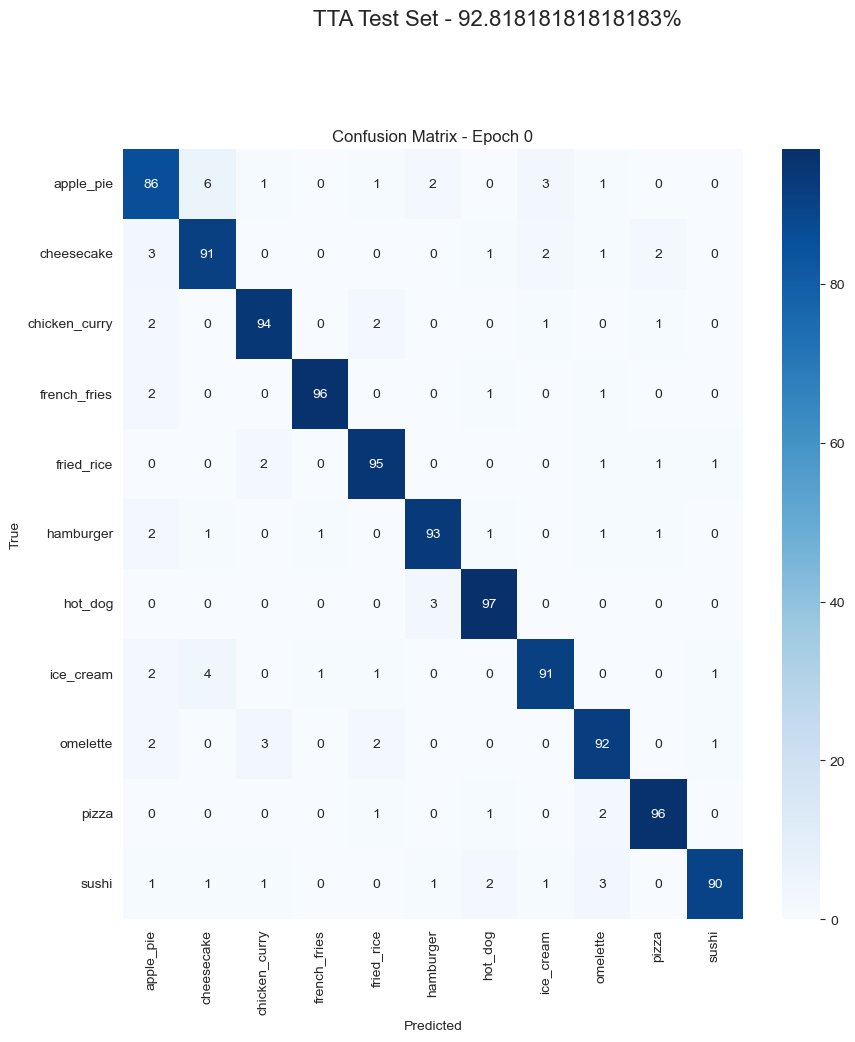

In [11]:
cm_tta = confusion_matrix(test_labels, test_preds)
cm_fig = plot_confusion_matrix(cm_tta, class_names, epoch=-1)
cm_fig.suptitle(f"TTA Test Set - {test_acc}%", fontsize=16, y=1.02)
cm_fig.savefig("FINAL_confusion_matrix_TTA_XXX%.png", dpi=200, bbox_inches='tight')
plt.show()